In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib widget


import os
os.chdir("/Users/nico/Documents/UCSB/research/LOBSTER")
from lobster_python import Dataset
import numpy as np
import matplotlib.pyplot as plt


from lobster_python.processing.response import extract_time_window , sliding_windows
from lobster_python.processing.psd import calculate_psd
from obspy import UTCDateTime, read_inventory, read
import numpy as np
import matplotlib.pyplot as plt


In [44]:
dataset = Dataset(
    name="DemoORCA",
    data_dir="/Users/nico/Documents/UCSB/research/ORCA/DemoORCA",
    response_dir="/Users/nico/Documents/UCSB/research/ORCA/PacORCA_database/RESP",
    metadata_file="/Users/nico/Documents/UCSB/research/LOBSTER/examples/mockORCA/mockORCAdb.csv"
)

# Discover data and construct objects
dataset.scan()

In [48]:
# successful UTCdatetime with data LOBSTER/PSD_dir/MM04/2019/11/19/4/CH0/PSD.pdf

from lobster_python.processing.response import extract_time_window , sliding_windows
from lobster_python.processing.psd import calculate_psd
from obspy import UTCDateTime, read_inventory, read
import numpy as np
import matplotlib.pyplot as plt

start_date = UTCDateTime("2020-07-01")
end_date = UTCDateTime("2020-08-01")

stations = ["MM04","MM05","MM06"]
channels = ["CH0","CH1","CH2","CH3"]

#identify station and channel (will be looped later)

# station = dataset.get_station("MM05")
# channel = station.get_channel("CH2")
# inventory = read_inventory(str(channel.response_file),format="RESP")

##### proposed loop structure #####
# loop over stations, get station data
# loop over channels, get channel data, build inventory response file
# loop over days, get files with identified day and merge traces
# loop over hours, cut daily data into hourly chunks

# testing opening hdf5 file to save data to
h5 = open_hdf5(
    "/Users/nico/Documents/UCSB/research/LOBSTER/examples/psd_database.h5",
    mode="a",
)

for station_idx in range(0,len(stations)):
    station = dataset.get_station(stations[station_idx])

    # plt.figure(figsize=(10,15))


    for channel_idx in range(0,len(channels)):
        print(f"working on {stations[station_idx]} {channels[channel_idx]}")

        channel = station.get_channel(channels[channel_idx])
        inventory = read_inventory(str(channel.response_file),format="RESP")

        for day_idx in range(int((end_date - start_date) / 86400) + 1):
            day         = start_date + (day_idx         * 86400)
            day_before  = start_date + ((day_idx - 1)   * 86400)
            day_after   = start_date + ((day_idx + 1)   * 86400)
            
            daily_channel_files  = channel.get_waveform_files(starttime=day_before,endtime=day_after)

            st = read(daily_channel_files[0])
            for file in daily_channel_files[1:]:
                st += read(file)

            st.merge(method=1, fill_value=None)
            tr = st[0]
            
            # try:
            #     hdf5_day_data = create_daily_group(h5,station=stations[station_idx],channel=channels[channel_idx],date=day.strftime("%Y-%m-%d"))
            # except ValueError:
            #     print('group already exists just keep it pushing')
            #     pass

            # plt.subplot(2*len(channels),1,2*channel_idx+1)
            # plt.plot(tr.times("matplotlib"),tr.data,alpha=0.5)
            # plt.title(f"{stations[station_idx]} {channels[channel_idx]}")

            hourly_psds = []

            for hour_idx in range(int((day_after-day)/ 3600)+1)[:-1]:
                hour = day + (hour_idx * 3600)
                hour_after = day + ((hour_idx+1) * 3600)
                hourly_data = extract_time_window(tr,starttime=hour,endtime=hour_after) 

                psds = []

                for windowed_data in sliding_windows(hourly_data,window_minutes=30):

                    psd = calculate_psd(windowed_data,sampling_rate=windowed_data.stats.sampling_rate)
                    frequency = psd[0]
                    psds.append(psd[1])
                
                psds = np.array(psds)
                median_psd = np.median(psds, axis=0)

                hourly_psds.append(median_psd)

            hourly_psds = np.array(hourly_psds)
            # print(hourly_psds.shape[0])
            # mean_hourly_psd = np.mean(hourly_psds, axis=0)
            # std_hourly_psd = np.std(hourly_psds,axis=0)

            # write_daily_psd(day=hdf5_day_data,frequency=frequency,hourly_median=hourly_psds,hourly_window_count=int(hourly_psds.shape[0]))


            # write_daily_psd(day.strftime("%Y-%m-%d")
            #                 day.strftime("%Y-%m-%d"),
            #                 frequency=frequency,
            #                 hourly_median=hourly_psds,
            #                 hourly_window_count=hourly_psds.shape[0],
            #                 hourly_mean=mean_hourly_psd,
            #                 hourly_std=std_hourly_psd,
            #                 psd_units="counts^2/Hz",
            #             )
    
                # median_psd = np.median(psd_array, axis=0)

    #         plt.subplot(2*len(channels),1,2*channel_idx+2)
    #         plt.loglog(psd[0],median_psd,alpha=0.5,c='grey')

    # plt.tight_layout()
    # plt.show()



#         std_median = np.std(median_psd)
#         std = np.std(psd)

#         median_stds.append(std_median)
#         stds.append(std)


        # for days


# for days in range(int((end_day - start_day) / 86400) + 1):
#     plt.figure(figsize=(12,6))
#     # print(days)
#     current_day = start_day + days * 86400
#     day_before = start_day + (days - 1) * 86400
#     next_day = start_day + (days + 1) * 86400

#     files = channel.get_waveform_files(
#         starttime=day_before,
#         endtime=next_day
#     )

#     st = read(files[0])
#     for file in files[1:]:
#         st += read(file)

#     st.merge(method=1, fill_value=None)
#     tr = st[0]
#     day_of_data = extract_time_window(tr,starttime=current_day,endtime=next_day) 


#     data = tr.data
#     times = tr.times("matplotlib")

#     data2 = day_of_data.data
#     times2 = day_of_data.times("matplotlib")

#     median_stds = []
#     stds = []

#     for hours in range(int((next_day-current_day)/ 3600)+1)[:-1]:
#         current_hour = current_day + hours * 3600
#         next_hour = current_day + (hours+1) * 3600
#         hour_of_data = extract_time_window(tr,starttime=current_hour,endtime=next_hour) 

#         psds = []
#         for window_trace in sliding_windows(hour_of_data,window_minutes=30):
            

#             psd = calculate_psd(window_trace,sampling_rate=window_trace.stats.sampling_rate)
#             psds.append(psd[1])

#         psds = np.array(psds)
#         median_psd = np.median(psds, axis=0)

#         std_median = np.std(median_psd)
#         std = np.std(psd)

#         median_stds.append(std_median)
#         stds.append(std)


working on MM04 CH0


KeyboardInterrupt: 

In [2]:
from lobster_python.hdf5.hdf5_io import *

# create_hdf5(
#     "../data/LOBSTER_output.h5",
#     overwrite=False,
# )

In [ ]:
# create_hdf5(
#      "/Users/nico/Documents/UCSB/research/LOBSTER/examples/psd_database.h5",
#     overwrite=False,
# )

h5 = open_hdf5(
    "/Users/nico/Documents/UCSB/research/LOBSTER/examples/psd_database.h5",
    mode="a",
)

# day = create_daily_group(
#     h5,
#     station="MM04",
#     channel="CH0",
#     date="2020-07-22",
# )

# write_daily_psd(
#     day,
#     frequency=frequency,
#     hourly_median=hourly_median,
#     hourly_window_count=hourly_window_count,
#     hourly_mean=hourly_mean,
#     hourly_std=hourly_std,
#     psd_units="counts^2/Hz",
# )

# write_waveform_references(
#     day,
#     waveform_files=waveform_files,
#     file_starttime=file_starttime,
#     file_endtime=file_endtime,
#     response_file="RESP/MM04/RESP.MM04.CH0",
# )

# record = read_daily_psd(
#     h5,
#     station="MM04",
#     channel="CH0",
#     date="2020-07-22",
# )

# frequency = record["frequency"]
# hourly_psd = record["hourly_median"]

# print(list(h5.keys()))

# print(list(h5["MM04/CH0/2020-07-22"].keys()))

# print(h5["MM04/CH0/2020-07-22/psd"].keys())

# close_hdf5(h5)

# print(
    
data = np.array(h5["MM04"]['CH0']['2020-07-22']['psd']['hourly_median'])
print(len(data[0,:]))
# print(data.shape[0])

# plt.figure()
# for i in range(0,data.shape[0]):
#     # print(i)
#     plt.loglog(np.array(h5["MM04"]['CH0']['2020-07-22']['psd']['frequency']),data[i,:])


# plt.show()

# print(len(np.array(h5["MM04"]['CH0']['2020-07-22']['psd']['frequency'])))

In [ ]:
def print_hdf5_structure(group):
    def print_item(name, obj):
        if isinstance(obj, h5py.Group):
            print(f"GROUP:   {name}")

        elif isinstance(obj, h5py.Dataset):
            print(
                f"DATASET: {name:50s} "
                f"Shape: {str(obj.shape):15s} "
                f"Datatype: {obj.dtype}"
            )

    group.visititems(print_item)


# print_hdf5_structure(h5)

h5['MM04']['CH0'].keys()

In [ ]:
def inspect_hdf5_sizes(h5):

    datasets = []

    def collect_sizes(name, obj):
        if isinstance(obj, h5py.Dataset):
            datasets.append({
                "name": name,
                "shape": obj.shape,
                "dtype": str(obj.dtype),
                "uncompressed_MB": obj.nbytes / 1e6,
                "stored_MB": obj.id.get_storage_size() / 1e6,
                "compression": obj.compression,
            })

    h5.visititems(collect_sizes)

    datasets.sort(
        key=lambda x: x["stored_MB"],
        reverse=True
    )

    for item in datasets:
        print(
            f"{item['stored_MB']:10.2f} MB | "
            f"{item['uncompressed_MB']:10.2f} MB | "
            f"{item['dtype']:8s} | "
            f"{str(item['shape']):18s} | "
            f"{str(item['compression']):8s} | "
            f"{item['name']}"
        )


inspect_hdf5_sizes(h5)

### visualization of PSDs from HDF5

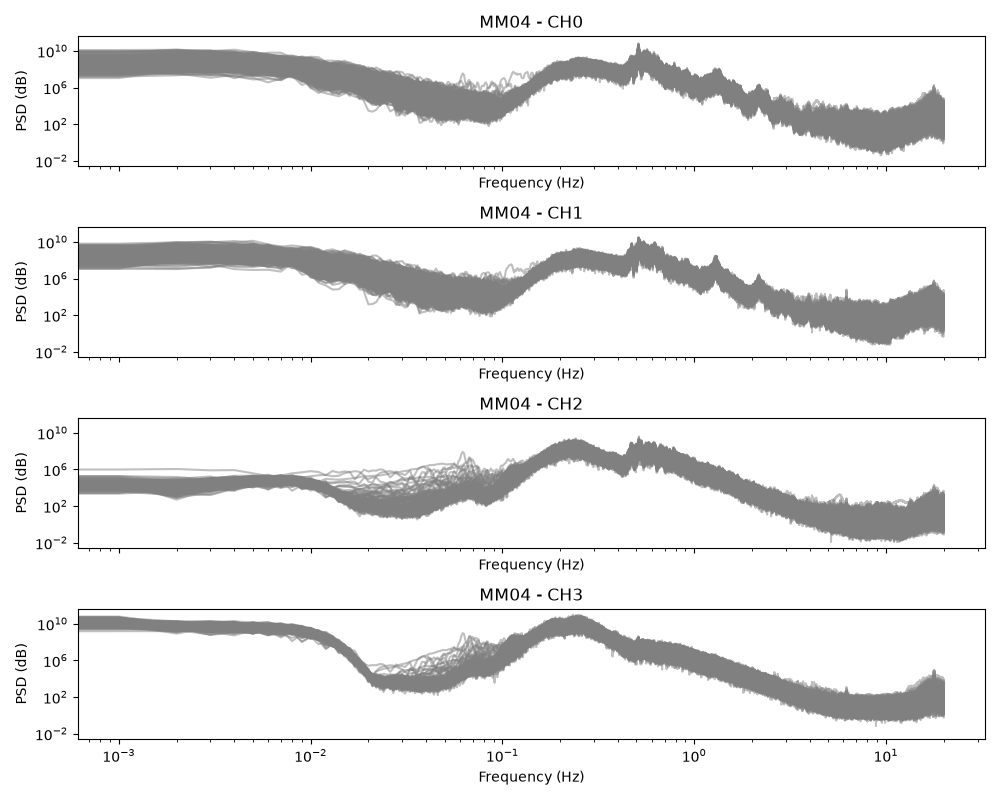

In [42]:
# data = np.array(h5["MM04"]['CH0']['2020-07-22']['psd']['hourly_median'])
# print(len(data[0,:]))
# print(data.shape[0])

start_date = UTCDateTime("2020-07-01")
end_date = UTCDateTime("2020-07-10")

stations = ["MM04"] #,"MM05","MM06"]
channels = ["CH0","CH1","CH2","CH3"]

# plt.figure()
# for i in range(0,data.shape[0]):
#     # print(i)
#     plt.loglog(np.array(h5["MM04"]['CH0']['2020-07-22']['psd']['frequency']),data[i,:],c='grey')


# plt.show()


h5 = open_hdf5(
    "/Users/nico/Documents/UCSB/research/LOBSTER/examples/psd_database.h5",
    mode="a",
)

fig, axes = plt.subplots(
    nrows=len(channels),
    ncols=len(stations),
    figsize=(10, 8),
    sharex=True,
    sharey=True,
    squeeze=False
)

for day_idx in range(int((end_date - start_date) / 86400) + 1):
    day         = start_date + (day_idx         * 86400)
    day_before  = start_date + ((day_idx - 1)   * 86400)
    day_after   = start_date + ((day_idx + 1)   * 86400)


    for station_idx in range(0,len(stations)):
        station = stations[station_idx]

        # plt.figure(figsize=(10,8))


        for channel_idx in range(0,len(channels)):
            # print(f"working on {stations[station_idx]} {channels[channel_idx]}")

            channel = channels[channel_idx]            
            data = np.array(h5[station][channel][day.strftime("%Y-%m-%d")]['psd']['hourly_median'])



            daily_psd = 10 * np.log10(np.median(data,axis=0))

            deviation = np.abs(data - daily_psd)

            hourly_score = np.nanmedian(deviation, axis=1)

            score_median = np.nanmedian(hourly_score)
            score_mad = np.nanmedian(np.abs(hourly_score - score_median))
            robust_sigma = 1.4826 * score_mad

            threshold = score_median + 3 * robust_sigma

            # Identify anomalous hours
            outliers = hourly_score > threshold

            # print("Flagged hours:", np.where(outliers)[0])

            


            # daily_psd = np.median(data,axis=0)

            frequency = np.array(h5[station][channel][day.strftime("%Y-%m-%d")]['psd']['frequency'])

            # plot_num = len(stations)*(station_idx+1) + len(channels)*(channel_idx)
            # print(plot_num)            
            # plt.subplot(len(stations),len(channels),1)

            # plt.title(f"{station}{channel}")
            # plt.semilogx(np.array(h5[station][channel][day.strftime("%Y-%m-%d")]['psd']['frequency']),daily_psd,c='grey',alpha=0.3)
            
            # ax = axes[station_idx, channel_idx]
            ax = axes[channel_idx, station_idx]

            for i in range(0,data.shape[0]):
                daily_psd = data[i,:]
                if outliers[i] is True:
                    ax.loglog(frequency, daily_psd,c='red',alpha=0.5)

            # Example plotting
                else:
                    ax.loglog(frequency, daily_psd,c='grey',alpha=0.5)

            ax.set_title(f"{station} - {channel}")
            ax.set_xlabel("Frequency (Hz)")
            ax.set_ylabel("PSD (dB)")
            # print(data.shape)
plt.tight_layout()
plt.show()


2020-07-20 | MM04 | CH0 | Flagged hours: [16 20 21 22 23]
2020-07-20 | MM04 | CH1 | Flagged hours: [16 20 21 22 23]
2020-07-20 | MM04 | CH2 | Flagged hours: [16 21 22 23]
2020-07-20 | MM04 | CH3 | Flagged hours: [16 20 21 22 23]


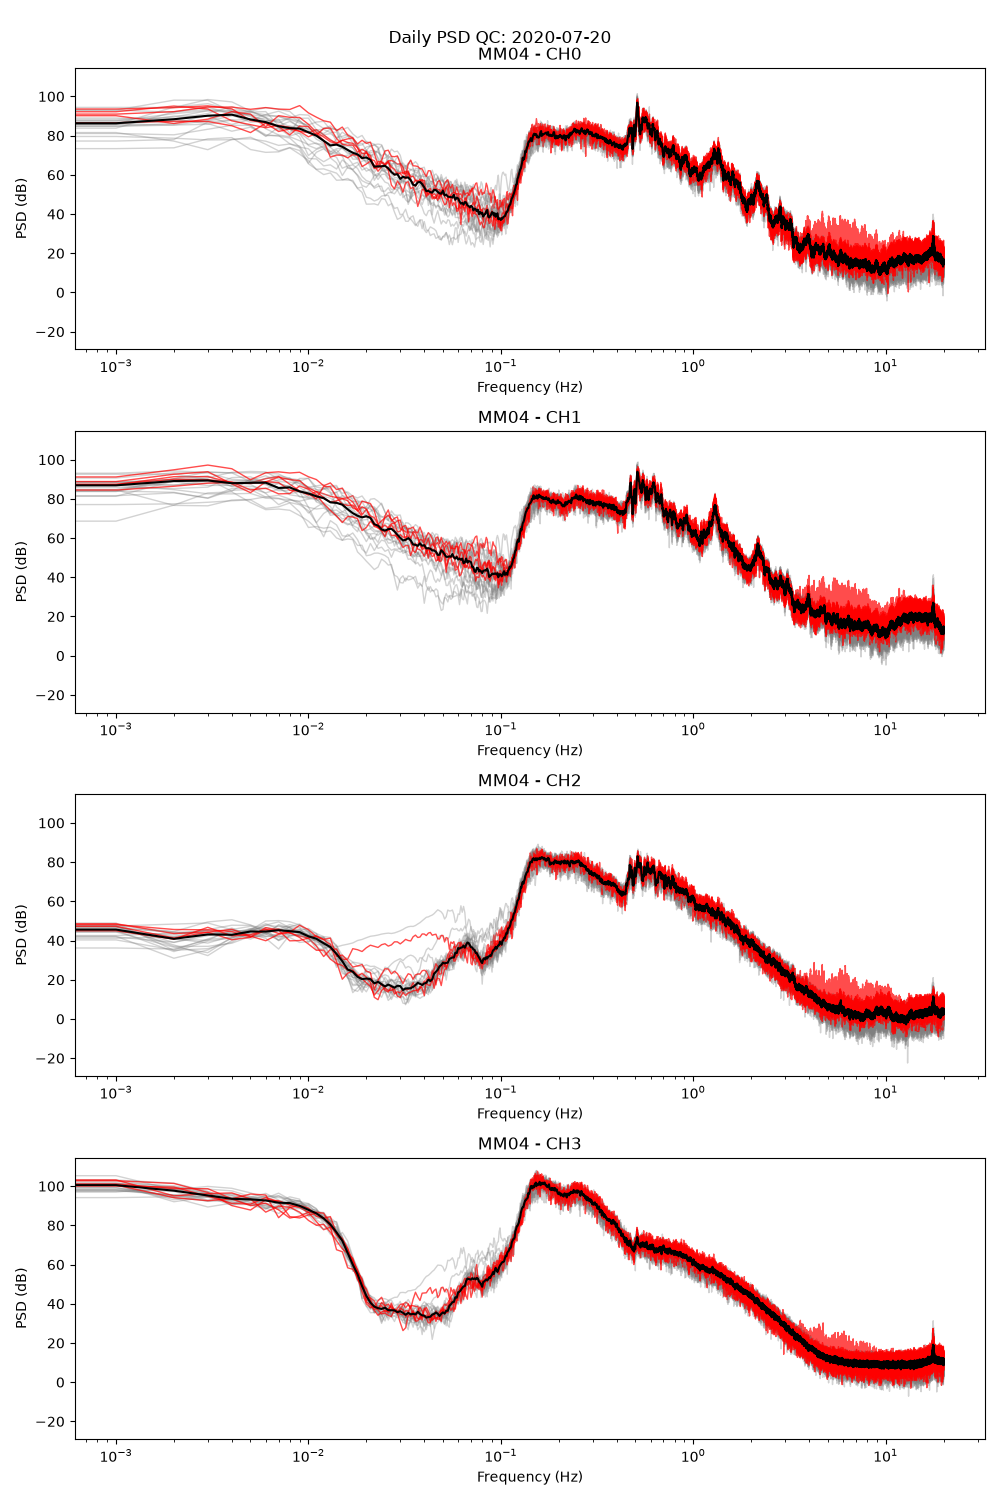

2020-07-21 | MM04 | CH0 | Flagged hours: [0 3]
2020-07-21 | MM04 | CH1 | Flagged hours: []
2020-07-21 | MM04 | CH2 | Flagged hours: [19]
2020-07-21 | MM04 | CH3 | Flagged hours: []


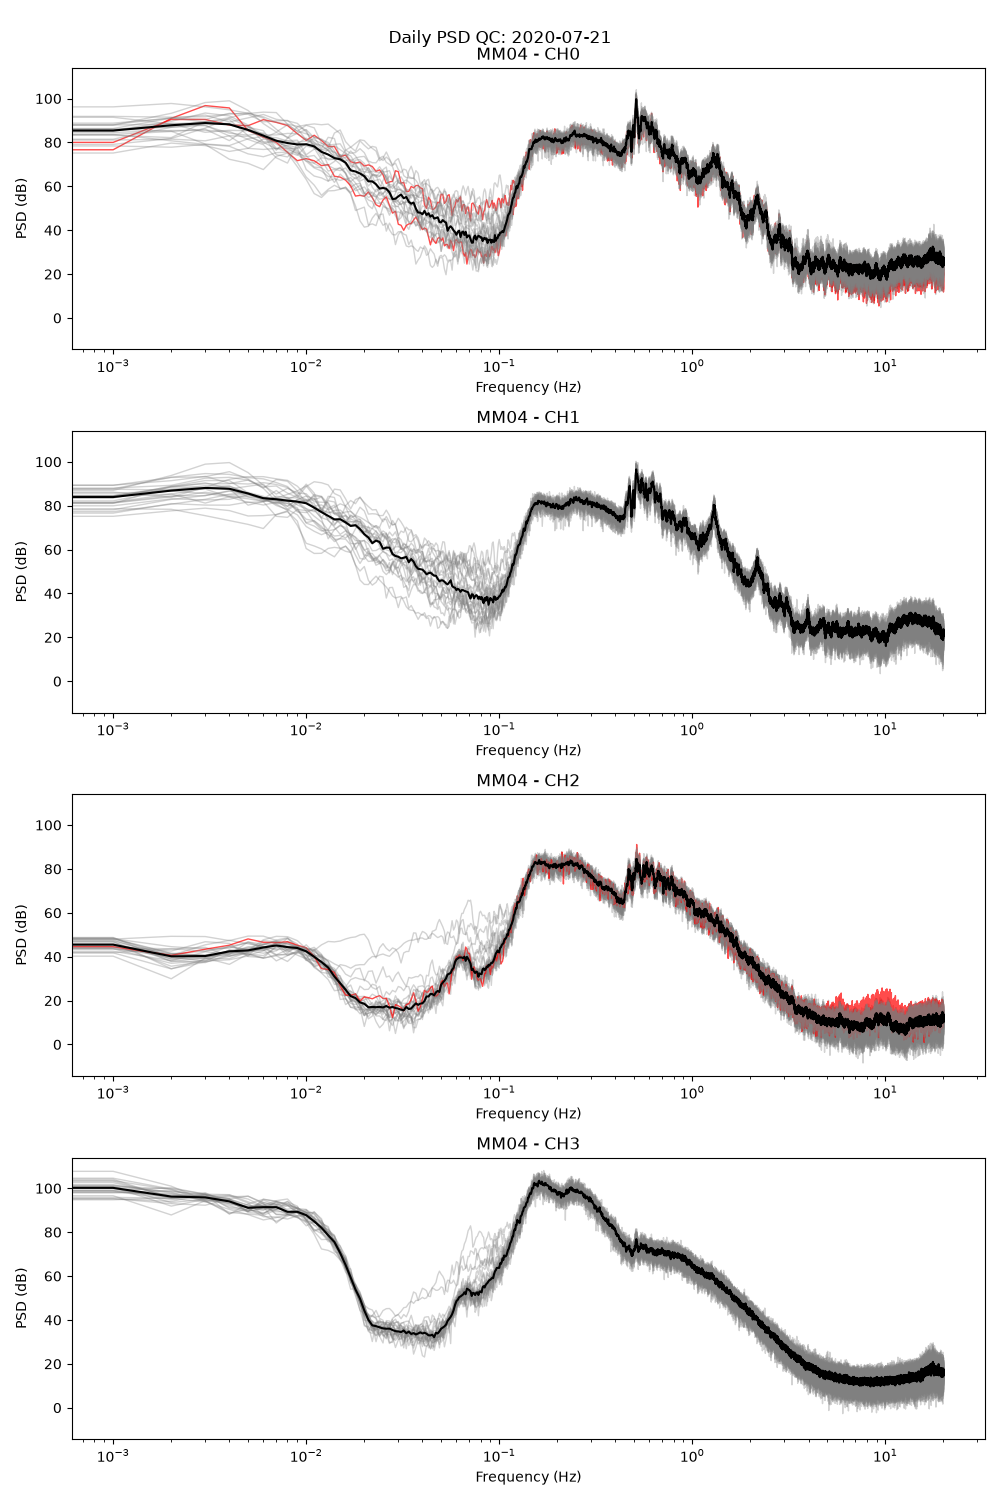

2020-07-22 | MM04 | CH0 | Flagged hours: [21 22 23]
2020-07-22 | MM04 | CH1 | Flagged hours: [21 22 23]
2020-07-22 | MM04 | CH2 | Flagged hours: [ 9 10 20 21 22 23]
2020-07-22 | MM04 | CH3 | Flagged hours: [21 22 23]


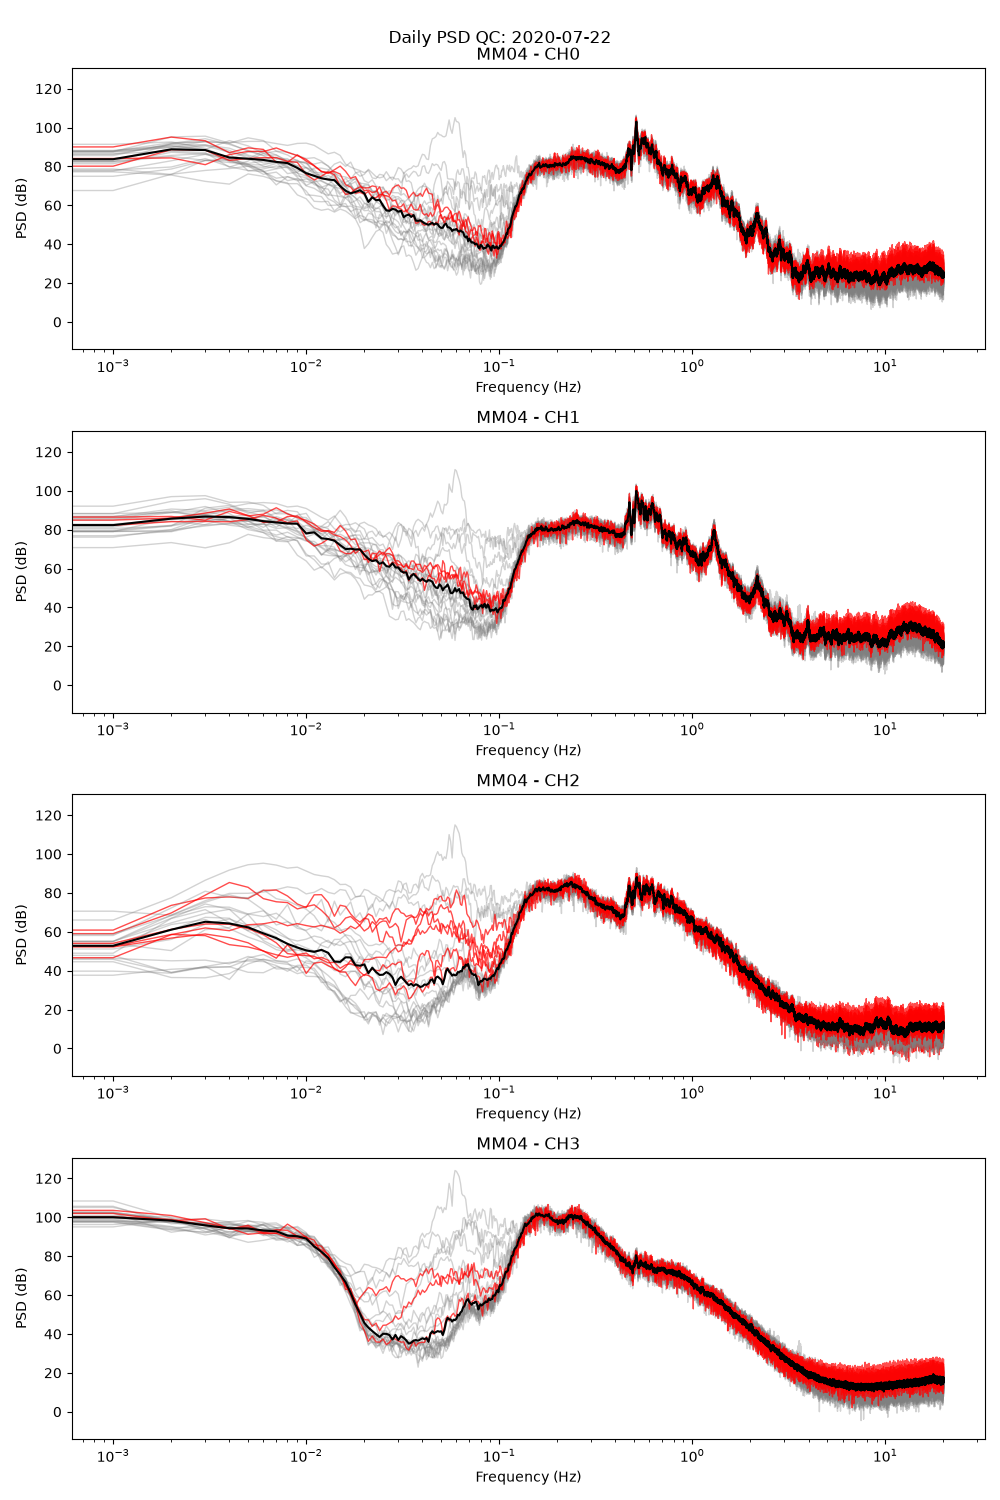

2020-07-23 | MM04 | CH0 | Flagged hours: [ 1 23]
2020-07-23 | MM04 | CH1 | Flagged hours: [ 0  1  2 23]
2020-07-23 | MM04 | CH2 | Flagged hours: [ 0  1  2 23]
2020-07-23 | MM04 | CH3 | Flagged hours: [ 0  1  2 23]


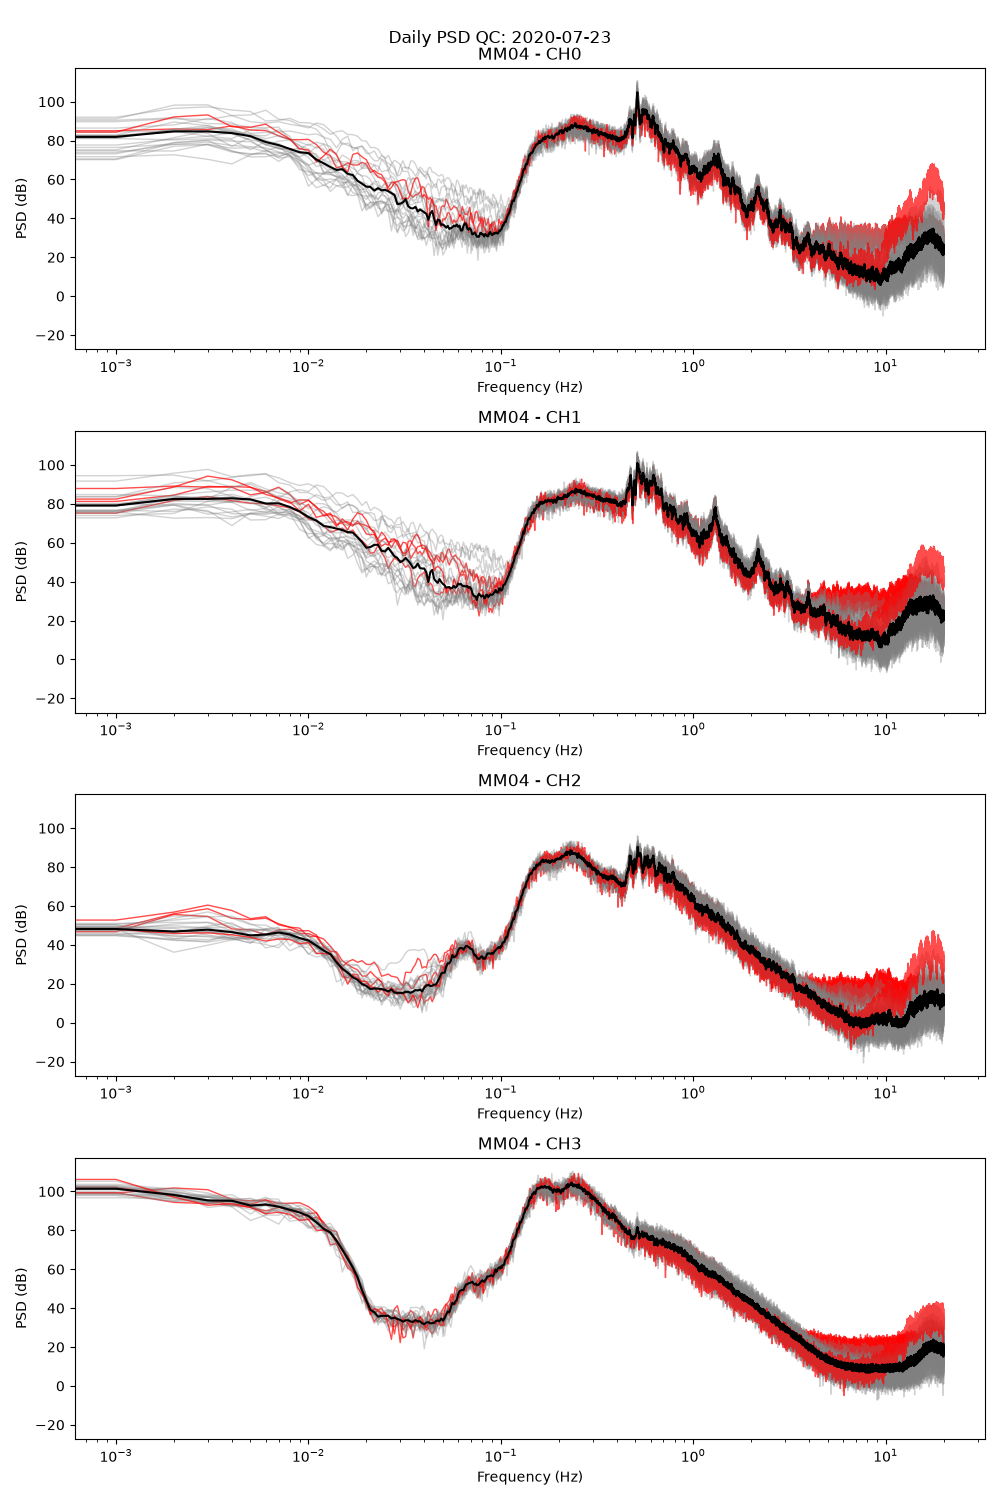

In [39]:
start_date = UTCDateTime("2020-07-20")
end_date = UTCDateTime("2020-07-23")

stations = ["MM04"]
channels = ["CH0", "CH1", "CH2", "CH3"]

h5 = open_hdf5(
    "/Users/nico/Documents/UCSB/research/LOBSTER/examples/psd_database.h5",
    mode="r",
)

for day_idx in range(int((end_date - start_date) / 86400) + 1):

    day = start_date + day_idx * 86400
    date_key = day.strftime("%Y-%m-%d")

    fig, axes = plt.subplots(
        nrows=len(channels),
        ncols=len(stations),
        figsize=(10, 15),
        sharex=False,
        sharey=True,
        squeeze=False
    )

    for station_idx, station in enumerate(stations):

        for channel_idx, channel in enumerate(channels):

            day_group = h5[station][channel][date_key]

            data = np.array(day_group["psd"]["hourly_median"])
            frequency = np.array(day_group["psd"]["frequency"])

            # Convert linear PSD to dB
            data_db = 10 * np.log10(np.where(data > 0, data, np.nan))

            # Calculate median spectrum across the 24 hours
            median_spectrum = np.nanmedian(data_db, axis=0)

            # Calculate deviation from median spectrum
            deviation = np.abs(data_db - median_spectrum)

            # One score per hour
            hourly_score = np.nanmedian(deviation, axis=1)

            # Calculate robust threshold
            score_median = np.nanmedian(hourly_score)
            score_mad = np.nanmedian(np.abs(hourly_score - score_median))
            robust_sigma = 1.4826 * score_mad

            threshold = score_median + 3 * robust_sigma

            # Identify anomalous hours
            outliers = hourly_score > threshold

            print(
                f"{date_key} | {station} | {channel} | "
                f"Flagged hours: {np.where(outliers)[0]}"
            )

            # Select subplot
            ax = axes[channel_idx, station_idx]

            # Plot each hourly PSD
            for hour_idx in range(data_db.shape[0]):

                if outliers[hour_idx]:
                    ax.semilogx(
                        frequency,
                        data_db[hour_idx],
                        color="red",
                        alpha=0.7,
                        linewidth=1
                    )
                else:
                    ax.semilogx(
                        frequency,
                        data_db[hour_idx],
                        color="grey",
                        alpha=0.35,
                        linewidth=1
                    )

            # Plot median spectrum
            ax.semilogx(
                frequency,
                median_spectrum,
                color="black",
                linewidth=1.5,
                label="Daily median"
            )

            ax.set_title(f"{station} - {channel}")
            ax.set_xlabel("Frequency (Hz)")
            ax.set_ylabel("PSD (dB)")

    fig.suptitle(f"Daily PSD QC: {date_key}")
    plt.tight_layout()
    plt.show()

h5.close()